# Beacon visual odometry: golden model, predicted performance, hardware evidence

Group 26, Wilson (M2). The robot measures its range to the bay's LED, and its speed, from the LED's elevation in the image. The LEDs are 150 mm above the lens, and the range drives the V4 stand-off: reverse until the robot is a set distance from the LED, with SW9 switching back to the timed V3 reverse. `golden/vo/README_VO.md` has the design.

1. **Predicted performance**: what the geometry can do, with no hardware.
2. **Drives in simulation**: the golden model on rendered drives, against exact ground truth.
3. **RTL vs model**: `vo_check.py`'s results, which must be bit for bit.
4. **Hardware**: photos from `vo_grab_top`, checked exactly against the model and against the tape. Calibration and the simulation-to-hardware gap.

In [1]:
import os, sys, json, shutil
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while not (ROOT / 'golden' / 'vo').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
VO = ROOT / 'golden' / 'vo'
for p in (VO, ROOT / 'golden', ROOT / 'golden' / 'framegrab', ROOT / 'golden' / 'framegrab' / 'vendor' / 'tools'):
    sys.path.insert(0, str(p))
import vo_model as vm, vo_scene as vs, vo_check as vc, vo_validate_grab as vv

for d in ('/opt/vsrc/verilator/bin',):
    if Path(d, 'verilator').exists() and not shutil.which('verilator'):
        os.environ['PATH'] = d + os.pathsep + os.environ['PATH']; os.environ.setdefault('VERILATOR_ROOT', str(Path(d).parent))
HAVE_RTL = shutil.which('verilator') is not None
RUN_RTL = HAVE_RTL          # run vo_check.py --quick below (about a minute)
cal, G = vv.load_calibration()
print('calibration:', cal['source'], '| f', cal['f_px'], 'px, pitch', cal['pitch_deg'], 'deg, DH', cal['dh_mm'], 'mm | Verilator:', HAVE_RTL)

calibration: default guess, not yet measured on the robot | f 560.0 px, pitch 12.0 deg, DH 150 mm | Verilator: True


## 1. Predicted performance

Each LED is drawn at distances from 0.3 to 2.5 m, centred and 300 mm to each side, and the integer RTL maths is run on it. The error that comes out is quantisation and centroid only. The dashed lines show what centroid noise of 0.25 and 0.5 px would cost; real blooming and exposure sit in that range. The right-hand plot shows where the LED sits in the image for different camera tilts. Above row 0 it is out of view, which is why the camera is tilted up.

worst model error 0.3-1.5 m: 4.0 mm


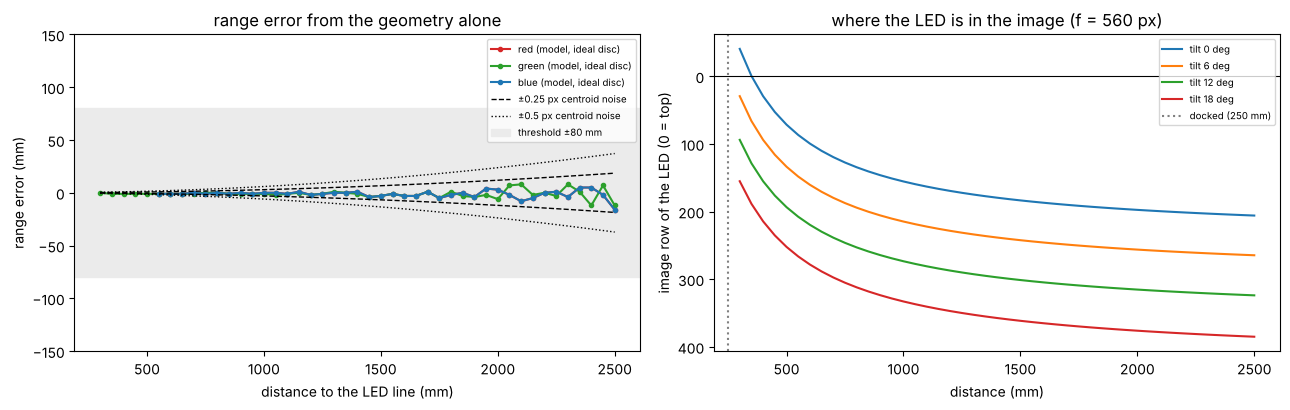

In [2]:
rig = vs.Rig(F_PX=G.F_Q4/16, CX=G.CX_Q4/16, CY=G.CY_Q4/16, H_LED=vs.Rig().H_CAM + G.DH_MM,
             PITCH_DEG=float(np.degrees(np.arcsin(G.SIN_Q14/16384))))
bg = np.zeros((480, 640), np.uint16)
D = np.arange(300, 2501, 50)
rows = []
for d in D:
    discs, truth = vs.frame_discs(rig, 0.0, -float(d), 0.0, (1, 1, 1))
    res = vm.geometry(vm.detect_frame(vs.render(bg, discs)), G)[0]
    for k in range(3):
        rows.append(dict(d=d, colour=vm.COLOURS[k], valid=res[k]['valid'],
                         err=res[k]['forward'] - truth[k]['forward'] if res[k]['valid'] else np.nan))
sweep = pd.DataFrame(rows)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for c, col in zip(vm.COLOURS, ('tab:red', 'tab:green', 'tab:blue')):
    s = sweep[sweep.colour == c]; ax[0].plot(s.d, s.err, 'o-', ms=3, color=col, label=f'{c} (model, ideal disc)')
for sig, ls in ((0.25, '--'), (0.5, ':')):
    ax[0].plot(D, D**2 * sig / (G.DH_MM * G.F_Q4/16), 'k' + ls, lw=1, label=f'±{sig} px centroid noise')
    ax[0].plot(D, -D**2 * sig / (G.DH_MM * G.F_Q4/16), 'k' + ls, lw=1)
ax[0].axhspan(-80, 80, color='0.92', zorder=0, label='threshold ±80 mm'); ax[0].set_ylim(-150, 150)
ax[0].set_xlabel('distance to the LED line (mm)'); ax[0].set_ylabel('range error (mm)'); ax[0].legend(fontsize=7)
ax[0].set_title('range error from the geometry alone')
for tilt in (0, 6, 12, 18):
    r2 = vs.Rig(F_PX=rig.F_PX, H_LED=rig.H_LED, PITCH_DEG=tilt)
    v = [vs.project(r2, *vs.robot_frame(r2, 0, -float(d), 0, 1))[1] for d in D]
    ax[1].plot(D, v, label=f'tilt {tilt} deg')
ax[1].axhline(0, color='k', lw=0.8); ax[1].axvline(250, color='0.5', ls=':', label='docked (250 mm)')
ax[1].invert_yaxis(); ax[1].set_xlabel('distance (mm)'); ax[1].set_ylabel('image row of the LED (0 = top)')
ax[1].set_title(f'where the LED is in the image (f = {rig.F_PX:.0f} px)'); ax[1].legend(fontsize=7)
fig.tight_layout()
print('worst model error 0.3-1.5 m: %.1f mm' % sweep[(sweep.d <= 1500)].err.abs().max())

## 2. Drives in simulation

These are `vo_scene.py`'s drives, with every frame drawn from the robot's true pose. Range and velocity are compared with the truth, and the stand-off marks the frame where the V4 decision fires.

,frames,n_range,range_max,range_mean,lat_max,n_vel,vel_max,vel_rms
scene,,,,,,,,
reverse_green,90,90,2.7,-0.7,0.0,86,21.6,7.3
approach_red_offset,80,80,4.6,-0.9,1.3,76,26.0,9.5
dropout_switch,40,32,1.7,-0.6,1.2,19,12.7,4.8
gates_distractors,12,9,2.6,-1.1,0.0,7,28.8,14.3


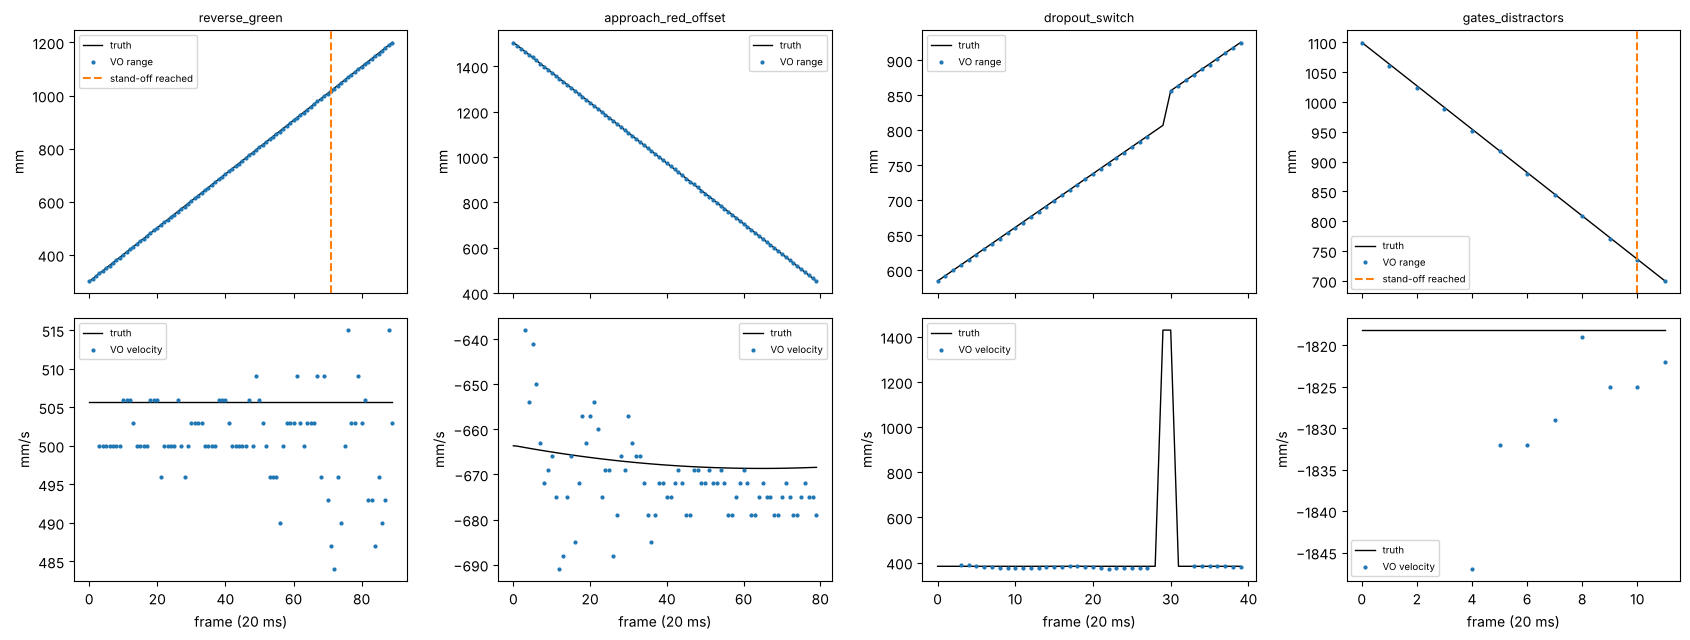

In [3]:
bgp = vs.background()
fig, axes = plt.subplots(2, 4, figsize=(17, 6.5), sharex='col')
acc_rows = []
for j, sc in enumerate(vs.scenarios(quick=False)):
    fr = vs.scenario_frames(sc, rig)
    frames = [vs.render(bgp, d) for d, _ in fr]
    res = vc.scene_model(sc, frames, rig)
    acc = vc.accuracy(sc, fr, res); acc_rows.append(dict(scene=sc.name, frames=len(res), **acc))
    i = np.arange(len(res))
    tr = np.array([fr[n][1][r['sel']]['forward'] for n, r in enumerate(res)])
    rng = np.array([r['trk']['range_mm'] if r['trk']['track_valid'] else np.nan for r in res])
    ax = axes[0, j]; ax.plot(i, tr, 'k-', lw=1, label='truth'); ax.plot(i, rng, '.', ms=4, label='VO range')
    hit = next((n for n, r in enumerate(res) if r['so']['reached']), None)
    if hit is not None: ax.axvline(hit, color='tab:orange', ls='--', label='stand-off reached')
    ax.set_title(sc.name, fontsize=9); ax.set_ylabel('mm'); ax.legend(fontsize=7)
    tv = np.gradient(tr) * 50
    vel = np.array([r['trk']['vel_mm_s'] if r['trk']['settled'] else np.nan for r in res])
    ax = axes[1, j]; ax.plot(i, tv, 'k-', lw=1, label='truth'); ax.plot(i, vel, '.', ms=4, label='VO velocity')
    ax.set_xlabel('frame (20 ms)'); ax.set_ylabel('mm/s'); ax.legend(fontsize=7)
fig.tight_layout()
pd.DataFrame(acc_rows).set_index('scene').round(1)

## 3. RTL vs golden model

`vo_check.py` runs the RTL in Verilator two ways:
- **Math fuzz**: geometry, tracker and stand-off on thousands of random and trajectory detections, with two calibrations.
- **Drive scenes**: through `camera_stream_adapter` and the whole `beacon_vo`, on two clocks with the clock-domain crossing.

Every output of every frame must equal the model. `--broken` swaps in a pitch-sign bug, and the run must print CAUGHT.

In [4]:
import subprocess
if RUN_RTL:
    r = subprocess.run([sys.executable, str(VO / 'vo_check.py'), '--quick'], capture_output=True, text=True, cwd=ROOT)
    lines = [l for l in r.stdout.splitlines() if l.startswith(('PASS', 'FAIL', 'CAUGHT'))]
    print('\n'.join(l[:220] for l in lines))
else:
    print('No Verilator here: run python golden/vo/vo_check.py on Ed or a machine with Verilator 5.050.')

PASS: vo math default: 1500 frames: 2830 LEDs placed, 506 rejected by the geometry, 974 pairs (528 consistent), 1389 tracked, 605 coasting, 46 drops, 111 restarts, 370 at stand-off: every output equals the model
PASS: vo math level_long: 1500 frames: 2535 LEDs placed, 586 rejected by the geometry, 858 pairs (465 consistent), 1302 tracked, 547 coasting, 37 drops, 70 restarts, 303 at stand-off: every output equals the model
PASS: vo scene reverse_green: 45 frames through the adapter, detect, CDC, geometry, tracker, stand-off: every detection and update equals the model; stand-off reached at frame 36
PASS: vo accuracy reverse_green: selected LED range error max 2.9 mm (mean -0.6) over 45 frames in 0.3-1.6 m, lateral max 0.0 mm; velocity error max 17 mm/s, rms 8 over 41 settled frames (limits 15 mm, 120 mm/s)
PASS: vo scene approach_red_offset: 40 frames through the adapter, detect, CDC, geometry, tracker, stand-off: every detection and update equals the model
PASS: vo accuracy approach_re

## 4. Hardware: photos from `vo_grab_top`

Every folder in `golden/framegrab/grabs/` with layout-2 words is a photo from the bench build. Three checks run on each:
- **KEPT** (exact): the board's detection against the model, on the photo.
- **GEOM** (exact): the board's millimetres against the model, from the board's own centroids.
- **tape**: against the tape, when the pose was recorded with `vo_take_photo.py --Y ...`.

The `sim_vo_*` folders come from the simulated board (`vo_grab_sim.py`). Real photos go beside them.

In [5]:
grabs = []
for d in sorted((ROOT / 'golden' / 'framegrab' / 'grabs').glob('*')):
    rj = d / 'results.json'
    if (d / 'dump.bin').exists():
        try:
            import validate_grab as fg; fg.ensure_decoded(d)
            if json.load(open(rj))['results'][1] >> 16 == 0x2602: grabs.append(d)
        except Exception as e:
            print('skip', d.name, e)
rows = []
for d in grabs:
    rep, s = vv.validate(d, (cal, G), echo=False)
    t = s['decoded']['track'] if s else {}
    tape = s['tape']['errors'] if s and s['tape'] else []
    rows.append(dict(photo=d.name, verdict='FAIL' if rep.fails else ('WARN' if rep.warns else 'PASS'),
                     tracking=vm.COLOURS[s['sel']] if s else '-', range_mm=t.get('range_mm'),
                     worst_tape_err_mm=max([abs(e['forward_err']) for e in tape], default=None),
                     checks='; '.join(f'{c}: {w}' for w, c, _ in rep.lines if w in ('PASS', 'FAIL', 'WARN') and c in ('KEPT (exact)', 'GEOM (exact)', 'tape'))))
pd.set_option('display.max_colwidth', 120)
pd.DataFrame(rows).set_index('photo') if rows else 'no VO photos yet: python golden/vo/vo_take_photo.py <name> --Y <mm>'

,verdict,tracking,range_mm,worst_tape_err_mm,checks
photo,,,,,
sim_vo_green_800,PASS,green,806,1.348959,KEPT (exact): PASS; GEOM (exact): PASS; tape: PASS
sim_vo_red_800,PASS,red,826,1.348959,KEPT (exact): PASS; GEOM (exact): PASS; tape: PASS


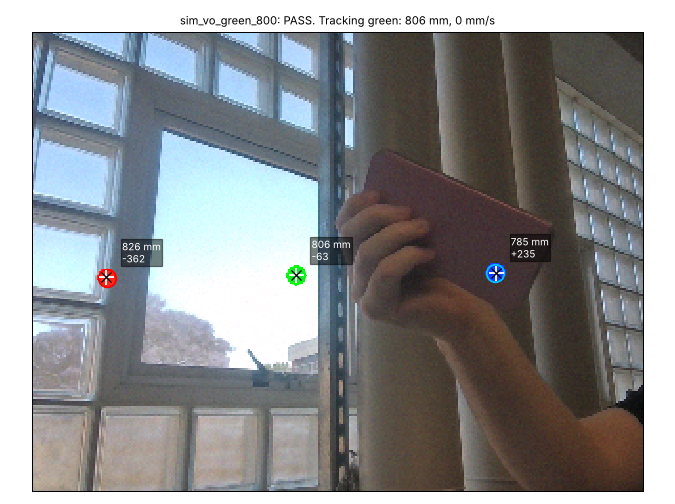

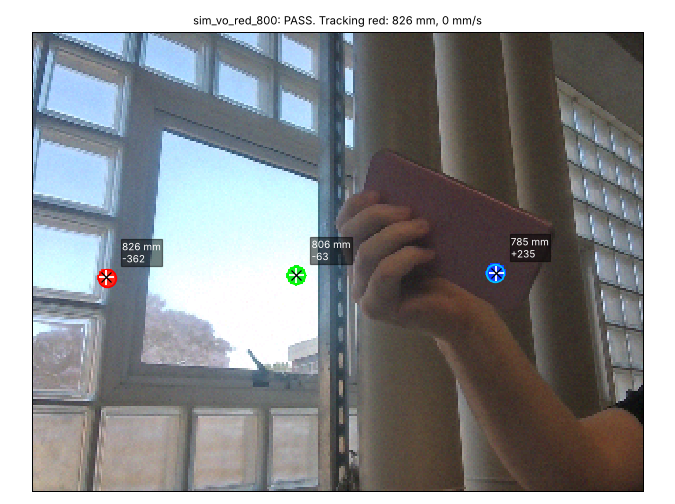

In [6]:
from IPython.display import Image, display
for d in grabs:
    if (d / 'vo_validation.png').exists(): display(Image(filename=str(d / 'vo_validation.png')))

### Range error against the tape, and the calibration

This is the simulation-to-hardware gap: real photos at taped distances against the model's prediction.
- **Before calibration**: the error is mostly scale, from the guessed focal length, pitch and DH.
- **After `vo_calibrate.py --write`** and a recompile: what remains is the hardware's own error (blooming, exposure, lens distortion, flatness of the floor). That remainder is the number for the datasheet.

6 LED measurements, worst 1 mm, mean -0.8 mm


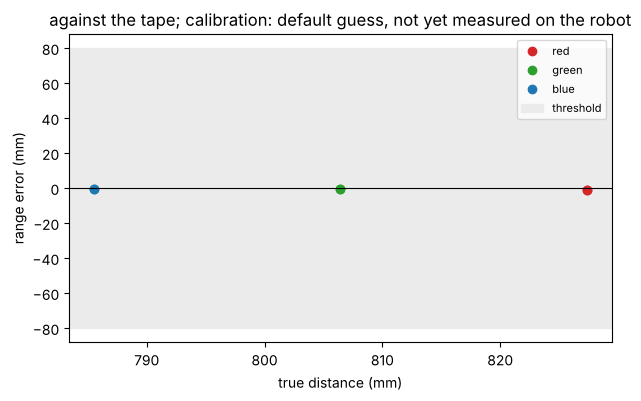

In [7]:
pts = []
for d in grabs:
    s = json.load(open(d / 'vo_validation.json'))
    for e in (s['tape']['errors'] if s.get('tape') else []):
        pts.append(dict(photo=d.name, colour=e['colour'], distance=e['forward_true'], error=e['forward_err']))
if pts:
    t = pd.DataFrame(pts)
    fig, ax = plt.subplots(figsize=(7, 4))
    for c, col in zip(vm.COLOURS, ('tab:red', 'tab:green', 'tab:blue')):
        s = t[t.colour == c]; ax.plot(s.distance, s.error, 'o', color=col, label=c)
    ax.axhspan(-80, 80, color='0.92', zorder=0, label='threshold'); ax.axhline(0, color='k', lw=0.8)
    ax.set_xlabel('true distance (mm)'); ax.set_ylabel('range error (mm)'); ax.legend(fontsize=8)
    ax.set_title(f"against the tape; calibration: {cal['source'][:60]}")
    print(f"{len(t)} LED measurements, worst {t.error.abs().max():.0f} mm, mean {t.error.mean():+.1f} mm")
else:
    print('no taped photos yet')

## Verdict

In [8]:
fails = sum(r['verdict'] == 'FAIL' for r in rows)
print(f"model geometry: worst {sweep[(sweep.d <= 1500)].err.abs().max():.1f} mm over 0.3-1.5 m; drives: worst {max(a['range_max'] for a in acc_rows):.1f} mm, velocity rms {max(a['vel_rms'] for a in acc_rows):.0f} mm/s")
print(f"{len(rows)} VO photo(s), {fails} failed")

model geometry: worst 4.0 mm over 0.3-1.5 m; drives: worst 4.6 mm, velocity rms 14 mm/s
2 VO photo(s), 0 failed
